In [26]:
options(repr.plot.width = 5, repr.plot.height = 3, repr.plot.res = 250)

In [27]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


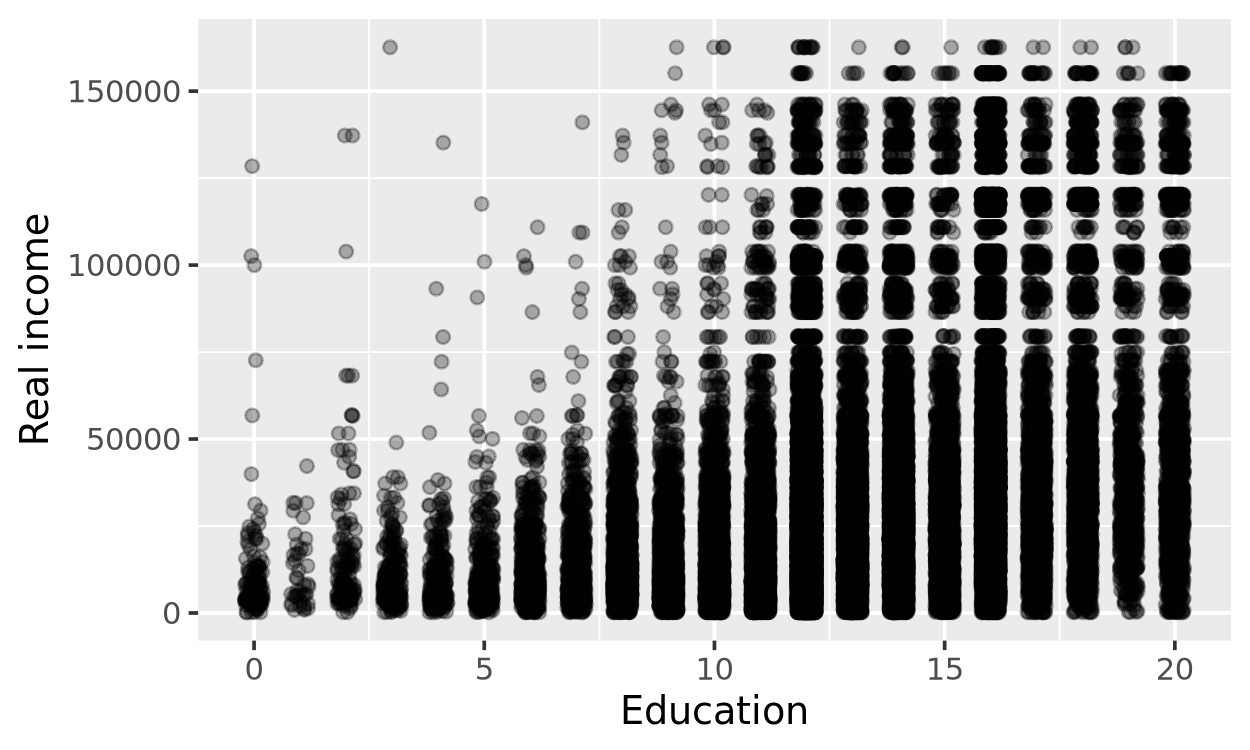

In [28]:
gss |>
  ggplot(aes(x = educ, y = realinc)) +
  geom_point(alpha = 0.3, position = position_jitter(width = 0.2, height = 0.2)) +
  labs(x = "Education", y = "Real income")

In [29]:
set.seed(512)

n_models <- 100

param_grid <- tibble(
  .model    = 1:n_models,
  intercept = runif(n_models, min = -50000, max = 100000),
  slope     = runif(n_models, min = -5000,  max = 10000)
)

param_grid |> glimpse()

Rows: 100
Columns: 3
$ .model    <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> 7799.908, -29920.001, 18513.888, 89865.118, 46562.336, -2039…
$ slope     <dbl> 5052.65701, 8970.66775, 2019.70081, 2908.19613, 9689.15344, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


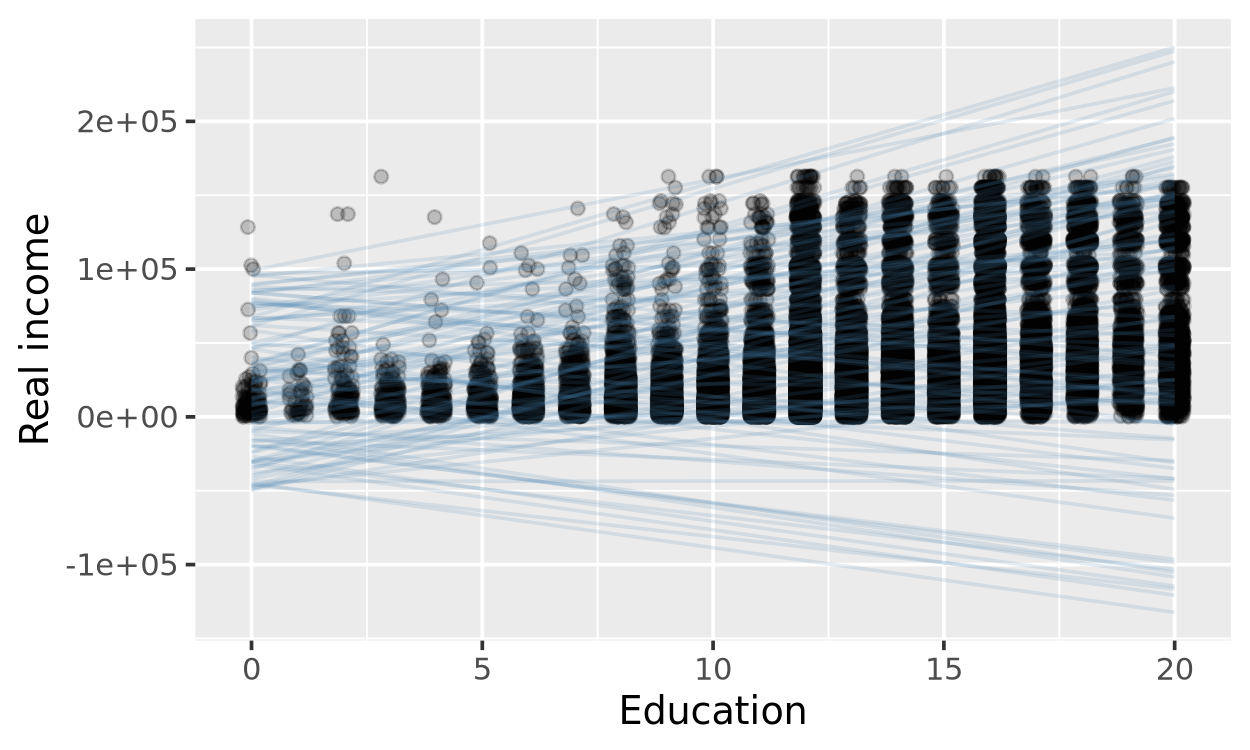

In [30]:
educ_seq <- tibble(educ = seq(0, 20, length.out = 100))

model_lines <- param_grid |>
  crossing(educ_seq) |>
  mutate(realinc = intercept + slope * educ)

gss |>
  ggplot(aes(x = educ, y = realinc)) +
  geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2)) +
  geom_line(
    data = model_lines,
    aes(group = .model),
    color = "steelblue",
    alpha = 0.15
  ) +
  labs(x = "Education", y = "Real income")

Steps for creating a model: 

1. Pick the model form: 
   $$\text{realinc} = \intercept + \slope \cdot \text{educ}$$
3. Design a way to evaluate different model parameters
4. Optimize our parameter values

In [31]:
calc_rmse <- function(intercept, slope, data = gss) {
  preds <- intercept + slope * data$educ
  sqrt(mean((data$realinc - preds)^2, na.rm = TRUE))
}

# Example: score a single parameter combination
calc_rmse(intercept = -20000, slope = 4000)

[1] 28331.55

In [32]:
intercept = 20000
slope = 10000

preds <- intercept + slope * gss$educ
sqrt(mean((gss$realinc - preds)^2, na.rm = TRUE))

[1] 123947

In [33]:
param_grid <- param_grid |>
  mutate(rmse = map2_dbl(intercept, slope, calc_rmse))

param_grid |>
  arrange(rmse) |>
  glimpse()

Rows: 100
Columns: 4
$ .model    <int> 16, 77, 17, 3, 59, 28, 41, 74, 78, 15, 93, 85, 24, 23, 52, 3…
$ intercept <dbl> -4128.912, -41808.412, -30405.522, 18513.888, -29864.252, 13…
$ slope     <dbl> 2644.13497, 5493.92419, 3917.73660, 2019.70081, 5799.62409, …
$ rmse      <dbl> 28516.55, 29017.64, 30543.30, 31333.01, 32280.78, 32301.25, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


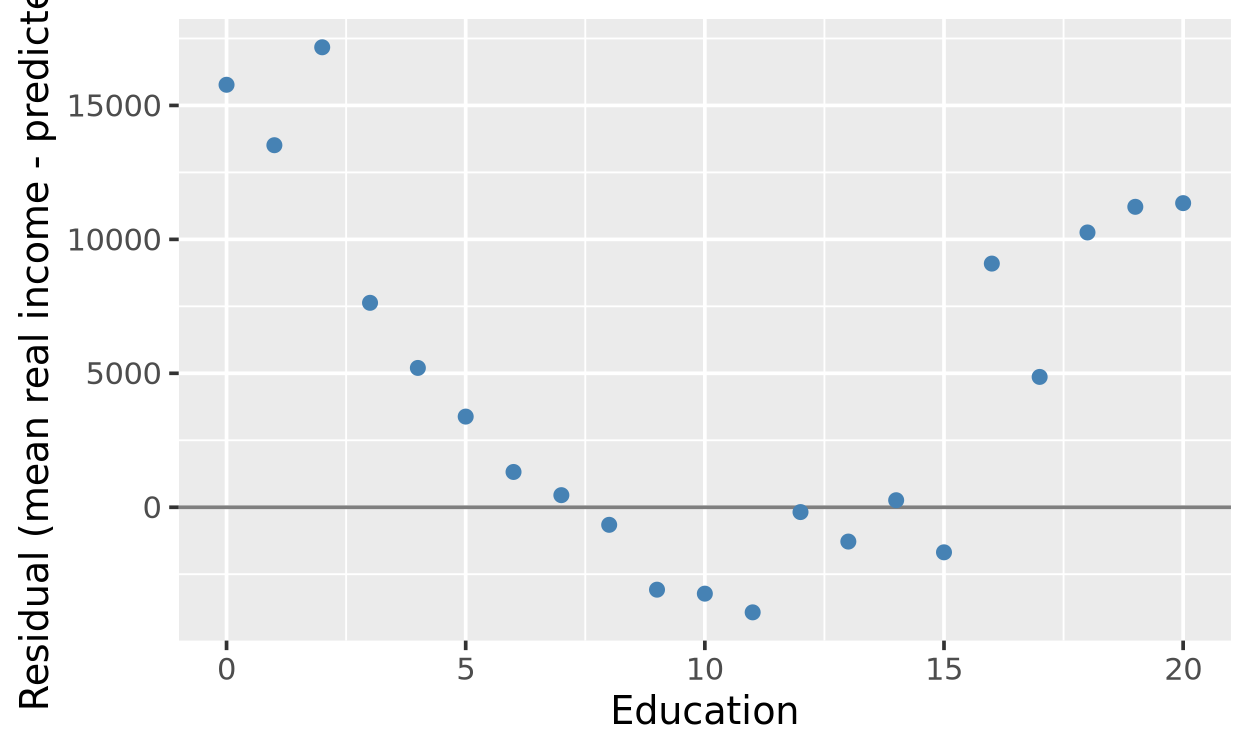

In [34]:
# Use the best-fitting combo so far (change this to inspect any other combo)
fit <- param_grid |> slice_min(rmse, n = 1)

gss_by_educ <- gss |>
  group_by(educ) |>
  summarise(mean_realinc = mean(realinc, na.rm = TRUE), .groups = "drop") |>
  mutate(
    predicted = fit$intercept + fit$slope * educ,
    residual  = mean_realinc - predicted
  )

gss_by_educ |>
  ggplot(aes(x = educ, y = residual)) +
  geom_hline(yintercept = 0, color = "grey50") +
  geom_point(color = "steelblue") +
  labs(x = "Education", y = "Residual (mean real income - predicted)")